# RecessionPop: is popular music a leading indicator of consumer sentiment?

**Question.** Does the mood of the Billboard Hot 100 (its lyrics, how it sounds, and its genre mix) carry information that improves one-month-ahead forecasts of the University of Michigan Consumer Sentiment Index (UMCSENT)?

**Data**

| Source | Role |
|---|---|
| Billboard Hot 100, weekly (1958–2026) | chart backbone: what was popular, and how popular |
| 550K Spotify Songs: Audio, Lyrics & Genres | audio features, genre tags, lyrics |
| NRC Emotion Lexicon v0.92 | word → emotion associations for lyric scoring |
| FRED `UMCSENT` | target: monthly consumer sentiment |

All data prep lives in `src/recessionpop/`. This notebook runs it, checks data quality, and evaluates the forecasts. The reasons behind each rule are in [`docs/decisions.md`](../docs/decisions.md).

## 1. Build the dataset

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from recessionpop import config as cfg
from recessionpop import modeling as m
from recessionpop.features import genre_shares
from recessionpop.pipeline import run

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

def savefig(name):
    plt.savefig(cfg.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

out = run()  # reuses cached stages in data/processed; run(force=True) rebuilds them

[   0.2s] Billboard: 354,858 weekly rows, 1958-07-30 to 2026-07-29


[   0.8s] 550K metadata with engineered genres: 550,622 rows


[   8.2s] Canonical title-artist lookup: 469,176 rows
[   8.2s] Unique Billboard songs matched: 11,976 / 32,592 (36.7%)
[   8.2s] Lyric features scored: 11,967 songs


[   9.0s] Model data: 240 months, 2001-01 to 2020-12


## 2. Match quality and the analysis window

Billboard songs are matched to the 550K catalogue in three conservative, deterministic passes. Only about 37% of *unique* songs match. Coverage of *popularity* matters more, so each chart row is weighted by `101 − Rank`.

In [2]:
out.song_matches["match_method"].fillna("unmatched").value_counts().to_frame("songs")

,songs
match_method,
unmatched,20616
exact_title_artist,10466
exact_title_lead_artist_after_featuring,798
exact_title_after_feature_strip_lead_artist_secondary_overlap,700
manual_ambiguous_feature_credit_review,12


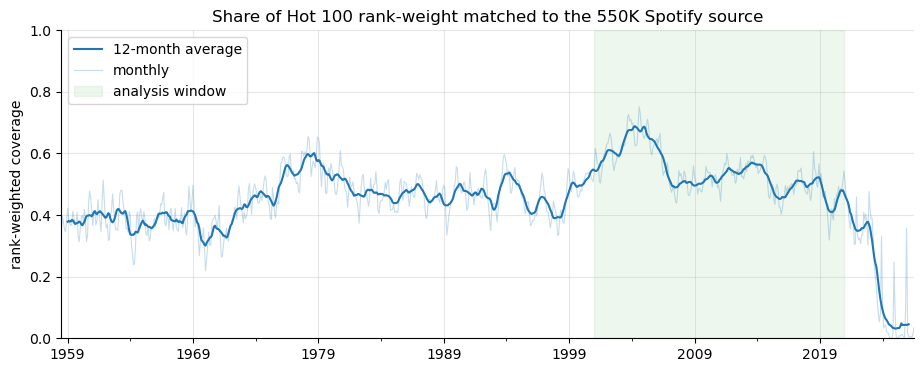

2001–2020 coverage: mean 54.1%, min 31.9%, months below 40%: 5


In [3]:
cov = out.monthly_coverage["rank_weighted_match_rate"]
fig, ax = plt.subplots()
cov.rolling(12, center=True).mean().plot(ax=ax, color="C0", label="12-month average")
cov.plot(ax=ax, color="C0", alpha=0.25, lw=0.8, label="monthly")
ax.axvspan(cfg.ANALYSIS_START, cfg.ANALYSIS_END, color="C2", alpha=0.08, label="analysis window")
ax.set(title="Share of Hot 100 rank-weight matched to the 550K Spotify source",
       ylabel="rank-weighted coverage", xlabel=None, ylim=(0, 1))
ax.legend(loc="upper left")
savefig("coverage")
plt.show()

window = cov.loc[cfg.ANALYSIS_START:cfg.ANALYSIS_END]
print(f"2001–2020 coverage: mean {window.mean():.1%}, min {window.min():.1%}, "
      f"months below 40%: {(window < 0.40).sum()}")

Coverage holds at about 50–60% through the 2000s and 2010s, then falls apart after 2020 as the 550K catalogue thins out. The analysis is therefore limited to **2001–2020**. Recent years are not padded with fuzzy matches.

## 3. The music signals

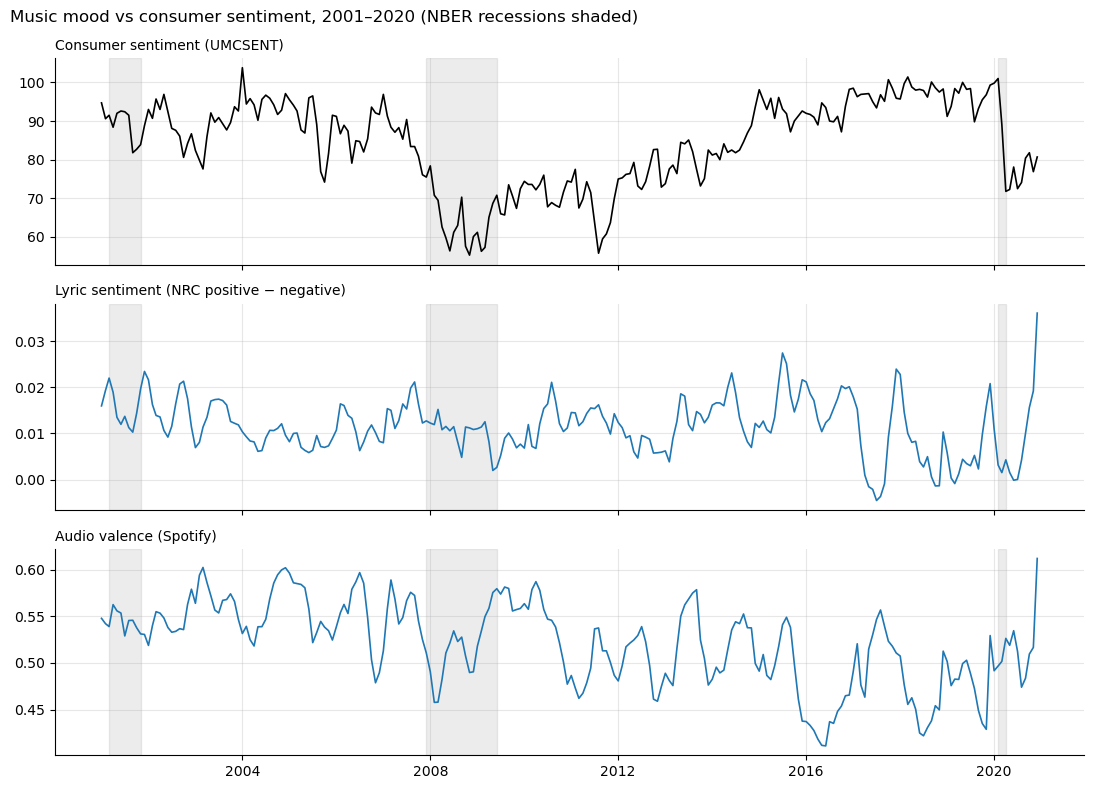

In [4]:
md_ = out.model_data
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, col, label in zip(
    axes,
    ["UMCSENT", "lyric_sentiment", "valence"],
    ["Consumer sentiment (UMCSENT)", "Lyric sentiment (NRC positive − negative)", "Audio valence (Spotify)"],
):
    ax.plot(md_["month"], md_[col], color="C0" if col != "UMCSENT" else "k", lw=1.2)
    ax.set_title(label, loc="left", fontsize=10)
for ax in axes:
    for s, e in [("2001-03-01", "2001-11-01"), ("2007-12-01", "2009-06-01"), ("2020-02-01", "2020-04-01")]:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="grey", alpha=0.15)
fig.suptitle("Music mood vs consumer sentiment, 2001–2020 (NBER recessions shaded)", x=0.01, ha="left")
fig.tight_layout()
savefig("signals")
plt.show()

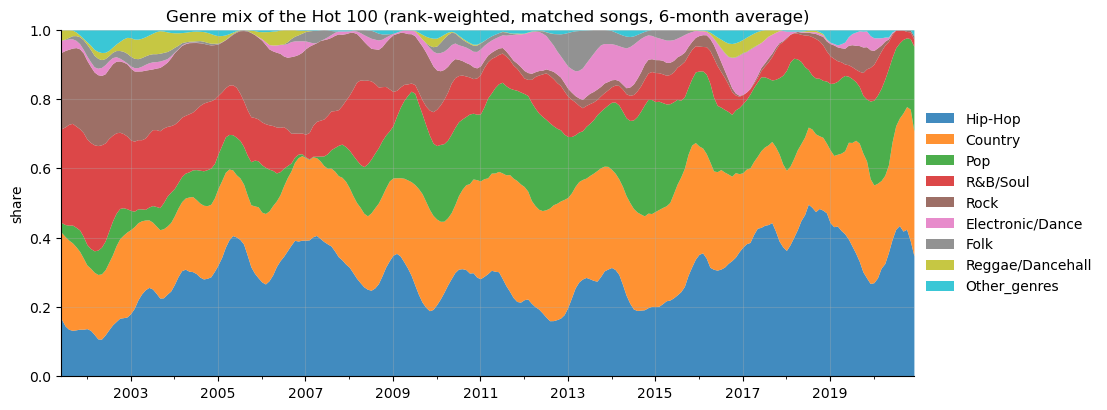

In [5]:
shares = genre_shares(out.weekly_chart)
top = shares.mean().sort_values(ascending=False).index[:8]
plot = shares[top].assign(Other_genres=shares.drop(columns=top).sum(axis=1))
ax = plot.rolling(6).mean().dropna().plot.area(figsize=(11, 4.5), lw=0, alpha=0.85, cmap="tab10")
ax.set(title="Genre mix of the Hot 100 (rank-weighted, matched songs, 6-month average)",
       ylabel="share", xlabel=None, ylim=(0, 1))
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
savefig("genre_mix")
plt.show()

## 4. Baseline: how hard is UMCSENT to forecast?

Train on 2001–2016 and test on 2017–2020. The tests below check whether sentiment behaves like a random walk.

In [6]:
mdl = m.add_signals(out.model_data)
train = mdl.loc[m.split_mask(mdl)].set_index("month")["UMCSENT"]

pd.DataFrame({
    "levels": m.adf_report(train),
    "first differences": m.adf_report(train.diff()),
}).T[["adf_stat", "p_value", "crit_5%"]]

,adf_stat,p_value,crit_5%
levels,-1.810,3.756e-01,-2.877
first differences,-10.206,5.806e-18,-2.877


In [7]:
m.arima_comparison(train)

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,order,AIC,BIC,ljung_box_p12,ljung_box_p24
0,"(1, 1, 1)",1094.678,1104.435,0.998,1.0
1,"(2, 1, 0)",1096.631,1106.388,0.990,1.0
2,"(0, 1, 0)",1098.579,1101.831,0.991,1.0
3,"(0, 1, 1)",1100.239,1106.744,0.991,1.0
4,"(1, 1, 0)",1100.360,1106.865,0.991,1.0


UMCSENT has a unit root in levels and is stationary after differencing. ARIMA terms on the differences barely change AIC, (0,1,0) has the best BIC, and its residuals already pass Ljung–Box. So the **random walk** ("next month equals this month") is the baseline to beat.

## 5. Does lagged music improve the forecast?

Each music model predicts **ΔUMCSENT(t)** from music at **t−1**: a no-intercept OLS fitted on the training window, with z-scores computed on training data only. It then adds that change to the random-walk forecast.

In [8]:
MODELS = {
    "core_sentiment (lyrics+valence)": ["core_sentiment_lag1"],
    "lyrics + valence (separate)": ["lyric_sentiment_z_lag1", "valence_z_lag1"],
}
results, forecasts, fits = m.evaluate(mdl, MODELS)
results

,MAE,RMSE,train_r2,min_p_value,RMSE_vs_rw_pct
model,,,,,
random_walk,2.927,4.326,NaN,NaN,0.000
core_sentiment (lyrics+valence),2.930,4.323,3.050e-05,0.939,-0.085
lyrics + valence (separate),2.945,4.342,7.033e-04,0.771,0.350


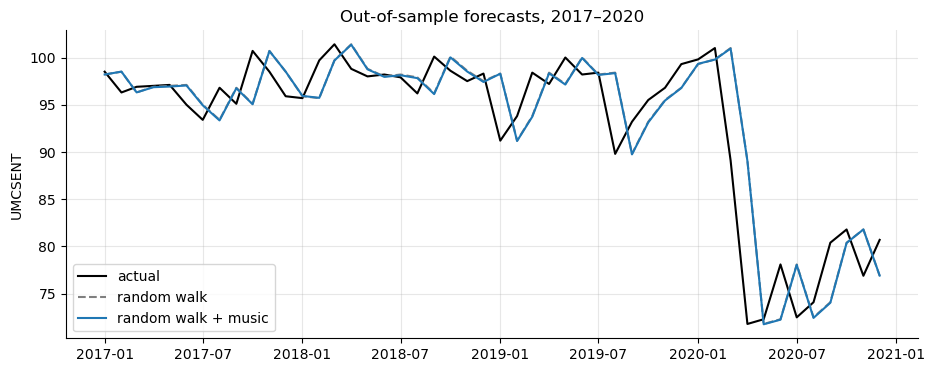

In [9]:
fig, ax = plt.subplots()
ax.plot(forecasts["month"], forecasts["UMCSENT"], "k", lw=1.5, label="actual")
ax.plot(forecasts["month"], forecasts["random_walk"], "C7", ls="--", label="random walk")
ax.plot(forecasts["month"], forecasts["core_sentiment (lyrics+valence)"], "C0", label="random walk + music")
ax.set(title="Out-of-sample forecasts, 2017–2020", ylabel="UMCSENT")
ax.legend()
savefig("forecasts")
plt.show()

## 6. Systematic predictor screen

Section 5 tested only one idea on one split. This section tests **every reasonable variant** with the same out-of-sample protocol (`src/recessionpop/predictors.py`).

- **Candidates:** 7 lyric emotion rates, 5 audio features, and the rank-weighted shares of the top 8 genres. Two controls set a reference point: inflation expectations (`MICH`), and last month's own change in sentiment.
- **Transforms:** level, 1-month change, 3-month change, and gap from the 12-month average, each at **lags of 1, 3 and 6 months**.
- **Rolling origin, 2008-01 to 2020-12 (156 forecasts):** each month the model is refit on past data only (z-scores included), so the Great Recession and COVID fall in the test period.
- **Test:** Clark–West for nested models (one-sided: does the candidate beat the random walk?), with Newey–West errors. With 255 candidates, about 13 would reach p < .05 by luck alone, so p-values are **Benjamini–Hochberg corrected** (q-values). Results are reported for the full window and for 2008–2019, which leaves out COVID.

In [10]:
from recessionpop import predictors as P
from recessionpop.load import load_mich_inflation

panel, groups = P.build_panel(out.model_data, shares, load_mich_inflation())
X, meta = P.build_candidates(panel, groups)
screen, oos_preds = P.screen(panel, X, meta, start="2008-01-01")

summary = screen.groupby("group").agg(
    candidates=("q_full", "size"),
    share_beating_rw=("rmse_ratio_full", lambda s: (s < 1).mean()),
    share_raw_p_below_05=("cw_p_full", lambda s: (s < 0.05).mean()),
    best_rmse_ratio=("rmse_ratio_full", "min"),
    min_q_full=("q_full", "min"),
    min_q_pre2020=("q_pre2020", "min"),
)
print(f"{len(screen)} candidates. Under pure noise, ~5% would show raw p < .05.")
summary

255 candidates. Under pure noise, ~5% would show raw p < .05.


,candidates,share_beating_rw,share_raw_p_below_05,best_rmse_ratio,min_q_full,min_q_pre2020
group,,,,,,
audio,60,0.167,0.017,0.990,0.999,1.0
control,15,0.133,0.000,0.998,0.999,1.0
genre,96,0.094,0.021,0.991,0.999,1.0
lyrics,84,0.071,0.000,0.997,0.999,1.0


In [11]:
cols = ["group", "rmse_ratio_full", "cw_p_full", "q_full",
        "rmse_ratio_pre2020", "cw_p_pre2020", "gain_recession", "gain_expansion"]
screen[cols].head(12)

,group,rmse_ratio_full,cw_p_full,q_full,rmse_ratio_pre2020,cw_p_pre2020,gain_recession,gain_expansion
candidate,,,,,,,,
valence|d1|L1,audio,0.990,0.017,0.999,0.993,0.066,0.260,0.347
share_R&B/Soul|dev12|L3,genre,0.991,0.022,0.999,0.994,0.055,2.801,-0.086
share_R&B/Soul|d3|L3,genre,0.994,0.037,0.999,0.991,0.019,0.284,0.184
danceability|dev12|L3,audio,0.997,0.064,0.999,1.001,0.191,0.197,0.093
share_Folk|d1|L3,genre,1.002,0.077,0.999,1.003,0.076,0.240,-0.123
share_Reggae/Dancehall|d1|L3,genre,0.998,0.094,0.999,0.997,0.095,0.026,0.092
negative_rate|d3|L6,lyrics,0.999,0.096,0.999,1.001,0.142,1.085,-0.133
share_Pop|d1|L1,genre,1.003,0.099,0.999,0.997,0.047,0.359,-0.196
negative_rate|dev12|L6,lyrics,1.010,0.100,0.999,1.015,0.138,3.596,-0.955


`rmse_ratio` below 1 means the candidate beat the random walk. `gain_*` is the average reduction in squared error during NBER recession months and during expansions; positive means better.

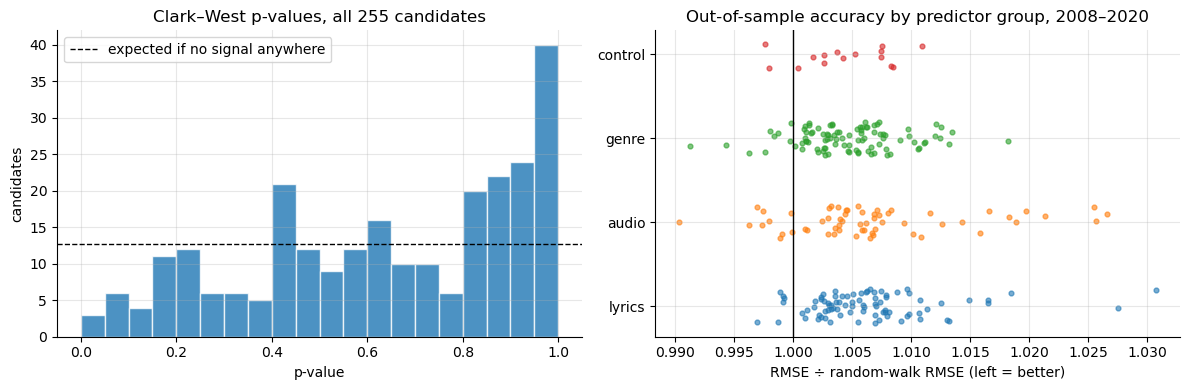

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(screen["cw_p_full"], bins=20, range=(0, 1), color="C0", alpha=0.8, edgecolor="white")
axes[0].axhline(len(screen) / 20, color="k", ls="--", lw=1, label="expected if no signal anywhere")
axes[0].set(title="Clark–West p-values, all 255 candidates", xlabel="p-value", ylabel="candidates")
axes[0].legend()

order = ["lyrics", "audio", "genre", "control"]
for i, g in enumerate(order):
    r = screen.loc[screen["group"] == g, "rmse_ratio_full"]
    axes[1].scatter(r, np.full(len(r), i) + np.random.default_rng(i).uniform(-0.2, 0.2, len(r)),
                    s=12, alpha=0.6, color=f"C{i}")
axes[1].axvline(1, color="k", lw=1)
axes[1].set(yticks=range(len(order)), yticklabels=order, xlabel="RMSE ÷ random-walk RMSE (left = better)",
            title="Out-of-sample accuracy by predictor group, 2008–2020")
fig.tight_layout()
savefig("predictor_screen")
plt.show()

If any candidates carried real signal, the p-value histogram would pile up near 0. Instead it is flat or skewed right. Nearly every candidate sits at or to the right of RMSE ratio 1: refitting on noise makes forecasts slightly *worse*.

### Could this test detect a real signal?

A null result only means something if the test could have found an effect. To check, I plant a synthetic predictor known at t−1 with a chosen true R² against next month's change, run it through the same rolling protocol 200 times, and count how often it's detected (p < .05).

In [13]:
rng = np.random.default_rng(42)
y = panel["dUMCSENT"].to_numpy()
y_std = (np.nan_to_num(y) - np.nanmean(y)) / np.nanstd(y)
power = {}
for r2 in [0.02, 0.05, 0.10]:
    hits = 0
    for _ in range(200):
        x = np.sqrt(r2) * y_std + np.sqrt(1 - r2) * rng.standard_normal(len(y))
        idx, p = P.rolling_forecasts(y, pd.Series(x), panel["month"], "2008-01-01")
        hits += P.clark_west(y[idx], p)[1] < 0.05
    power[f"true R² = {r2:.0%}"] = hits / 200
pd.Series(power, name="detection rate").to_frame()

,detection rate
true R² = 2%,0.320
true R² = 5%,0.810
true R² = 10%,0.985


### Joint models and economic controls

Small effects could add up across features. So next I fit whole blocks jointly, and check whether the best single candidates add anything beyond the economic controls in-sample, using HAC-robust regressions.

In [14]:
lyr = [f"{f}|d1|L1" for f in P.LYRIC_FEATURES]
aud = [f"{f}|d1|L1" for f in P.AUDIO_FEATURES]
gen = [c for c in X.columns if c.startswith("share_") and c.endswith("|d1|L1")]
blocks = {
    "all lyric emotions (Δ, t−1)": lyr,
    "all audio features (Δ, t−1)": aud,
    "genre mix (Δ, t−1)": gen,
    "lyrics + audio + genre (Δ, t−1)": lyr + aud + gen,
    "top-3 screened candidates": list(screen.index[:3]),
}
block_res = pd.DataFrame([P.evaluate_block(panel, X, c, name=n) for n, c in blocks.items()]).set_index("candidate")
block_res[["rmse_ratio_full", "cw_p_full", "rmse_ratio_pre2020", "cw_p_pre2020"]]

,rmse_ratio_full,cw_p_full,rmse_ratio_pre2020,cw_p_pre2020
candidate,,,,
"all lyric emotions (Δ, t−1)",1.025,0.417,1.018,0.184
"all audio features (Δ, t−1)",1.028,0.594,1.045,0.823
"genre mix (Δ, t−1)",1.043,0.302,1.035,0.169
"lyrics + audio + genre (Δ, t−1)",1.136,0.361,1.149,0.299
top-3 screened candidates,0.987,0.005,0.985,0.008


The "top-3 screened candidates" row is optimistic on purpose: those three were chosen *by looking at* this same test window, so they have an unfair advantage.

In [15]:
top = [c for c in screen.index if meta.loc[c, "group"] != "control"][:5]
pd.DataFrame(
    [P.granger_with_controls(panel, X, c) | {"sample": "2001–2020"} for c in top]
    + [P.granger_with_controls(panel, X, c, end="2020-01-01") | {"sample": "2001–2019"} for c in top]
).set_index(["sample", "candidate"]).round(3)

coef      t      p    n
sample    candidate                                         
2001–2020 valence|d1|L1           -30.049 -2.306  0.021  238
          share_R&B/Soul|dev12|L3 -12.611 -2.480  0.013  226
          share_R&B/Soul|d3|L3     -9.866 -1.960  0.050  234
          danceability|dev12|L3    25.417  2.004  0.045  226
          share_Folk|d1|L3         46.398  2.183  0.029  236
2001–2019 valence|d1|L1           -28.111 -1.881  0.060  226
          share_R&B/Soul|dev12|L3 -10.438 -1.920  0.055  214
          share_R&B/Soul|d3|L3    -10.920 -2.123  0.034  222
          danceability|dev12|L3    18.732  1.392  0.164  214
          share_Folk|d1|L3         49.057  2.205  0.027  224

## 7. The reverse question: does sentiment lead the music?

Music might *follow* the public mood instead of anticipating it. A recession could, with a delay, shift what people stream, buy and request on radio. So the roles are flipped here (`src/recessionpop/reverse.py`):

- **Target:** the monthly change in each of the 20 music series (lyric emotions, audio features, genre shares).
- **Baseline:** an AR(2) on the music series' own past changes, because chart mood is persistent and a fair test has to beat that.
- **Augmented model:** the baseline plus one lagged sentiment variable: ΔUMCSENT at t−1, t−3 or t−6, or the 3-month change ending at t−1. That gives 80 variants.
- **Test:** the same rolling-origin protocol from 2008 to 2020, the nested Clark–West test, and the Benjamini–Hochberg correction.

In [16]:
from recessionpop import reverse as R

rev = R.reverse_screen(panel, groups, start="2008-01-01")
print(f"{len(rev)} variants | raw p < .05: {(rev['cw_p_full'] < .05).sum()} "
      f"(chance ≈ {0.05 * len(rev):.0f}) | best q full: {rev['q_full'].min():.2f}, "
      f"best q 2008–2019: {rev['q_pre2020'].min():.2f}")
rev.head(10).set_index(["feature", "sentiment_predictor"])

80 variants | raw p < .05: 1 (chance ≈ 4) | best q full: 0.98, best q 2008–2019: 0.40


,,group,rmse_ratio_full,cw_p_full,rmse_ratio_pre2020,cw_p_pre2020,q_full,q_pre2020
feature,sentiment_predictor,,,,,,,
valence,3-mo dU to t-1,audio,0.994,0.044,0.990,0.058,0.981,0.992
share_Reggae/Dancehall,dU t-6,genre,0.994,0.070,0.992,0.069,0.981,0.992
energy,dU t-6,audio,0.997,0.111,0.991,0.005,0.981,0.404
share_Electronic/Dance,dU t-6,genre,0.996,0.126,0.992,0.043,0.981,0.992
valence,dU t-3,audio,0.996,0.133,1.001,0.547,0.981,0.992
share_Country,dU t-3,genre,0.996,0.133,1.001,0.650,0.981,0.992
tempo,3-mo dU to t-1,audio,0.998,0.169,0.998,0.231,0.981,0.992
share_R&B/Soul,3-mo dU to t-1,genre,0.997,0.170,0.999,0.264,0.981,0.992
tempo,dU t-1,audio,0.999,0.194,1.001,0.325,0.981,0.992


### Granger tests in both directions

These are in-sample, 2001–2020. Each regression has an intercept, 3 own lags, and 3 lags of the other variable, with HAC-robust F-tests. Both directions are run on exactly the same footing, so they can be compared directly.

In [17]:
gr = R.granger_both_ways(panel, groups, k=3)
print("raw p < .05 — music→sentiment:", (gr["p_music_to_sentiment"] < .05).sum(),
      "| sentiment→music:", (gr["p_sentiment_to_music"] < .05).sum(), f"(chance ≈ {0.05 * len(gr):.0f} each)")
gr[["group", "p_music_to_sentiment", "q_music_to_sentiment",
    "p_sentiment_to_music", "q_sentiment_to_music"]].round(3)

raw p < .05 — music→sentiment: 2 | sentiment→music: 0 (chance ≈ 1 each)


,group,p_music_to_sentiment,q_music_to_sentiment,p_sentiment_to_music,q_sentiment_to_music
feature,,,,,
lyric_sentiment,lyrics,0.697,0.774,0.318,0.862
positive_rate,lyrics,0.449,0.599,0.457,0.862
negative_rate,lyrics,0.131,0.481,0.564,0.862
anger_rate,lyrics,0.290,0.481,0.719,0.886
fear_rate,lyrics,0.017,0.170,0.664,0.885
joy_rate,lyrics,0.336,0.481,0.515,0.862
sadness_rate,lyrics,0.901,0.901,0.603,0.862
valence,audio,0.104,0.481,0.123,0.862
energy,audio,0.328,0.481,0.304,0.862


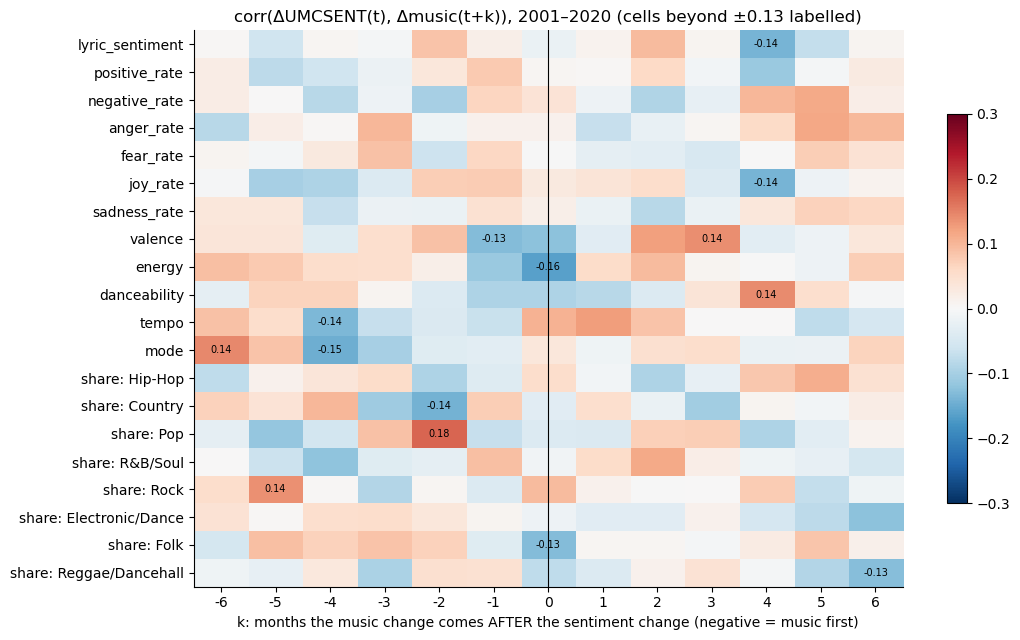

14 of 260 correlations fall outside the ±0.13 band; ~13 expected by chance.


In [18]:
cc = R.cross_correlations(panel, groups, max_lag=6)
band = 1.96 / np.sqrt(panel["UMCSENT"].diff().notna().sum())

fig, ax = plt.subplots(figsize=(11, 6.5))
im = ax.imshow(cc.values, cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
ax.set_xticks(range(cc.shape[1]), cc.columns)
ax.set_yticks(range(cc.shape[0]), [i.replace("share_", "share: ") for i in cc.index])
for (i, j), v in np.ndenumerate(cc.values):
    if abs(v) > band:
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
ax.axvline(cc.columns.get_loc(0), color="k", lw=0.8)
ax.set(xlabel="k: months the music change comes AFTER the sentiment change (negative = music first)",
       title=f"corr(ΔUMCSENT(t), Δmusic(t+k)), 2001–2020 (cells beyond ±{band:.2f} labelled)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout()
savefig("cross_correlations")
plt.show()

n_out = int((cc.abs() > band).sum().sum())
print(f"{n_out} of {cc.size} correlations fall outside the ±{band:.2f} band; ~{0.05 * cc.size:.0f} expected by chance.")

### Power check for the reverse test

As before, I plant a synthetic music series whose monthly change truly depends on last month's sentiment change, at a chosen R². It keeps the real valence series' own history and noise, and goes through the identical rolling protocol.

In [19]:
R.power_check(panel, feature="valence", reps=200).to_frame()

,detection rate
true R² = 2%,0.365
true R² = 5%,0.830
true R² = 10%,0.985


## 8. Findings

1. **Music mood doesn't predict next month's consumer sentiment, and the test could have shown it if it did.** None of 255 candidates (lyric emotions, audio features or genre mix, across 4 transforms and 3 lags) survives the false-discovery correction (best q ≈ 1.0). Fewer candidates reach raw p < .05 than pure chance would produce. The same protocol detects a planted predictor with R² = 5% most of the time, so any real effect is smaller than that.
2. **Joint models don't help.** Fitting lyrics, audio and genre blocks together does worse than the random walk, which is the usual cost of estimating extra coefficients with no signal behind them.
3. **The best-looking single candidates are what multiple testing produces.** The top screen hits are 1-month valence changes and R&B's chart share (out-of-sample RMSE about 1% better, raw p ≈ 0.02). Picking the best 3 of 255 and testing them on the same window *should* look significant, and it does (p = 0.005), which is exactly why the correction exists. Their in-sample HAC p-values sit around 0.01–0.05 and get weaker once 2020 is dropped. The valence sign is also backwards from the hypothesis: more upbeat-sounding charts precede *falling* sentiment.
4. **Context:** inflation expectations and sentiment's own past changes don't beat the random walk at a one-month horizon either. Month-to-month moves in UMCSENT are mostly unpredictable surprises, so "no music signal" is partly "no signal at this horizon, period."
5. **Music doesn't follow sentiment either.** Past sentiment changes don't help forecast chart mood beyond its own history: 1 of 80 variants reaches raw p < .05 (about 4 expected by chance), and the best q is 0.98 (0.40 for 2008–2019). In-sample Granger tests find *no* sentiment→music effect at raw p < .05 for any of the 20 series. The music→sentiment direction has two raw hits (fear rate, Pop share), and neither survives correction.
6. **There's no co-movement at all.** Same-month correlations between sentiment changes and music changes are all near zero (|r| ≤ 0.16). Of 260 lead or lag correlations, 14 fall outside the 95% band, against about 13 expected by chance, and they're scattered with no consistent row or direction. The power check detects a planted 5% effect most of the time, so the same bar applies in this direction.

**Bottom line.** Over 2001–2020, the rank-weighted mood of the Hot 100 moves independently of consumer sentiment, month to month, in either direction and at lags of up to 6 months. That covers lyrics, sound and genre mix alike.

**What this does and doesn't rule out.** These results cover *monthly changes* in a national index, measured through a 54%-coverage Spotify match and lexicon-based lyric scoring. They don't rule out:

- slower, year-scale cultural shifts, though 20 years gives only about 20 independent annual observations;
- effects that show up only in specific groups (for example, new releases rather than the whole chart, or particular genres' own audiences);
- signals that need better lyric models than a word lexicon.